# Ejercicio 2: algoritmo de ejecución estilo TWAP aprendido por recompensas

Se parte del entorno y del agente Double DQN (PyTorch) del Ejercicio 1 y se cambia el objetivo: el agente debe repartir la orden CARE de compra en el tiempo como un **TWAP**, es decir, mantener el volumen ejecutado sobre la diagonal `V·t/T` con órdenes hijas de tamaño 1, sin impacto ni costes.

La regla determinista es trivial (si se va por detrás del plan, se compra; si se va por delante, se espera). Lo que se pide es que el agente llegue a ese comportamiento **solo a través de la recompensa**, y que lo haga para cualquier día, hora de inicio, duración del episodio (400 a 600 bins de 5 s) y tamaño de orden (7,5 % a 12,5 % de los bins).

El cuaderno tiene dos partes, como el enunciado:

1. **Recompensas**: estado, recompensa, por qué, y gráficos del comportamiento resultante.
2. **Parametría**: γ, α, buffer, frecuencia de aprendizaje, etc., con la motivación y un barrido con varias semillas que la respalda.

## Bloques modificados respecto al Ejercicio 1

| Bloque | Cambio | Fichero |
|---|---|---|
| (3) `observation_builder` | `state_mode="plan"`: se añade al estado el desvío frente al plan, en títulos y acotado | `env.py` |
| (6) `_compute_reward` | `reward_mode="twap"`: `r = -κ·|desvío|` tras cada acción | `env.py` |
| (12) `_compute_done_reward` | castigo por volumen pendiente al agotar el tiempo y valor descontado del desvío restante si la orden se completa antes | `env.py` |
| `reset(seed)` | episodios reproducibles sin tocar el RNG global, para evaluar siempre sobre el mismo panel | `env.py` |
| (4) y (5) | caché en `numpy` del mid y de las sumas acumuladas del VWAP (mismo resultado, unas 5 veces más rápido) | `env.py` |
| `DDQNAgent` | `force_first_buy=False`: la primera compra también la decide la política | `experiments.py` |
| `TWAP` | admite `horizon` (se usa en el Ej. 4B); sigue siendo la regla determinista del taller | `agents.py` |
| Bucle | `train_with_evaluation`: el mismo bucle `reset, act, step, experience, learn, update_target`, más una evaluación greedy cada 5 episodios sobre 20 episodios fijos | `train.py` |
| Métricas | `run_episode`, `evaluate_panel`: desvío medio frente al plan, % fuera de plan, % completado, % de tiempo usado, slippage en pbs | `evaluation.py` |

Los valores por defecto de `reward_mode` y `state_mode` siguen siendo los del Ejercicio 1, que se reproduce igual.

In [1]:
from pathlib import Path
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# src al path, relativo a la raíz del repositorio
repo_root = Path.cwd().resolve()
if not (repo_root / "src").exists():
    repo_root = repo_root.parent
if str(repo_root / "src") not in sys.path:
    sys.path.insert(0, str(repo_root / "src"))

from execution_rl import *  # noqa: F403
from execution_rl.experiments import (
    PANEL_SEEDS,
    ExperimentConfig,
    build_agent,
    build_env,
    build_scheduler,
    eval_curves,
    restore_agent,
    run_many,
    save_results_table,
    twap_panel,
    with_seeds,
)

SEED = 42
set_seeds(SEED)
results_dir = repo_root / "results"
results_dir.mkdir(parents=True, exist_ok=True)
# procesos para los barridos con varias semillas
N_JOBS = max(1, min(12, (os.cpu_count() or 2) - 2))
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
print(f"Procesos en paralelo: {N_JOBS}")

Procesos en paralelo: 12


## Primera parte: estado

El estado tiene tres variables, todas normalizadas:

| Variable | Definición | Rango |
|---|---|---|
| tiempo restante | `(T - t) / T` | [0, 1] |
| volumen restante | `1 - ejecutado / V` | [0, 1] |
| desvío frente al plan | `clip((ejecutado - V·t/T) / 5, -1, 1)` | [-1, 1] |

**Por qué estas variables.** Un TWAP no mira el mercado: su decisión depende solo de dónde se está respecto al calendario. Con tiempo y volumen restantes el estado ya es markoviano para esta tarea (es lo que se indicó en clase), y al expresarlo en porcentajes es estacionario y no depende de la duración ni del tamaño de la orden. No se añaden variables de mercado porque el enunciado excluye impacto y costes y el objetivo no depende del precio.

**Por qué el desvío.** Con solo dos variables la frontera entre comprar y esperar es la diagonal `volumen restante = tiempo restante`, pero con una precisión de `1/V` (entre 1,3 % y 3,3 % según la orden), y como `V` no está en el estado, la red tiene que aprender una franja muy estrecha. El desvío en títulos es redundante en información, pero convierte la frontera en el signo de una sola variable, igual para cualquier `V` y `T`. En la segunda parte se comparan ambos estados: con dos variables también se aprende, pero más despacio y con más dependencia de la semilla.

Las acciones son las del taller: 0 esperar, 1 comprar un título a `ask1`.

## Primera parte: recompensa

Con `plan(t) = V·t/T` y `desvío(t) = ejecutado(t) - plan(t)`:

$$r_t = -\kappa\,\lvert \text{desvío}(t+1) \rvert, \qquad \kappa = 0{,}2$$

Al cerrar el episodio:

* **Tiempo agotado con `P` títulos pendientes**: $-\kappa\,\lambda\,P$, con $\lambda = 2$.
* **Orden completa en el step `t < T`**: $-\kappa \sum_{k=1}^{T-t} \gamma^k \,\lvert V - \text{plan}(t+k) \rvert$, el valor descontado del desvío que habría acumulado el episodio si siguiera sin decisiones.

**Por qué así.**

* *Aterriza el objetivo.* Un TWAP es "estar sobre la diagonal": la recompensa es exactamente la distancia a ella. Ir por delante (comprar antes de tiempo) penaliza igual que ir por detrás, por eso el valor absoluto.
* *Densa.* Cada acción tiene consecuencia inmediata, sin depender de una recompensa final a 500 steps vista. Con γ < 1 una recompensa solo al final sería casi invisible al principio del episodio ($0{,}99^{500} \approx 0{,}7\,\%$).
* *Magnitud.* Con κ = 0,2, ir 5 títulos fuera del plan cuesta 1 por step; un TWAP se mueve en $\lvert\text{desvío}\rvert < 1$, es decir, en $[-0{,}2,\ 0]$ por step. Recompensas en $[-1, 0]$ y valores Q de orden unidad hacen estable el ajuste de la red.
* *Cierre coherente.* Todos los steps cuestan $\le 0$, así que terminar antes cortaría las penalizaciones y premiaría correr. El término de orden completa cobra lo que faltaba del horizonte, con el mismo γ del agente, de modo que el episodio se valora siempre sobre su duración completa. Una primera versión sin descontar ese término (una suma de cientos de títulos·step) hundía Q(comprar) en todos los estados y el agente aprendía a no comprar nunca: la magnitud del cierre importa tanto como su signo.
* *Volumen pendiente.* λ = 2 hace que dejar títulos sin ejecutar sea más caro que cualquier desvío de un step, sin dominar el resto de la señal.

La celda siguiente comprueba que la recompensa ordena bien comportamientos conocidos sobre el mismo panel de 20 episodios: el TWAP debe ser el mejor y las políticas que corren, esperan o no compran, claramente peores.

In [2]:
cfg = ExperimentConfig(name="estado plan, γ=0,9", seed=SEED)
env = build_env(cfg)


class RulePolicy(DDQNAgent):
    """Política fija para comprobar cómo puntúa la recompensa cada comportamiento."""

    def __init__(self, env: BestExecutionEnv, rule) -> None:
        super().__init__(env, force_first_buy=False)
        self.rule = rule

    def act(self, s: np.ndarray) -> int:
        return int(self.rule(self.env))


policies = {
    "TWAP determinista": TWAP(env, force_first_buy=False),
    "TWAP doble velocidad (acaba al 50 %)": TWAP(env, horizon=0.5, force_first_buy=False),
    "comprar todo al inicio": RulePolicy(env, lambda e: 1),
    "comprar todo al final": RulePolicy(env, lambda e: int(e.episode_bins - e.state_pos <= e.vol_care - e.exec_vol)),
    "aleatoria (p = V/T)": RulePolicy(env, lambda e: e.action_sample()),
    "no comprar": RulePolicy(env, lambda e: 0),
}
set_seeds(SEED)
rows = []
for name, pol in policies.items():
    summ = summarize_panel(evaluate_panel(env, pol, PANEL_SEEDS))
    rows.append({"política": name, **{k: summ[k] for k in ["cum_reward", "mean_abs_dev", "completed_pct", "time_used_pct"]}})
reward_check = pd.DataFrame(rows).set_index("política").sort_values("cum_reward", ascending=False)
save_results_table(reward_check.reset_index(), results_dir / "ej2_reward_check.csv")
reward_check

,cum_reward,mean_abs_dev,completed_pct,time_used_pct
política,,,,
TWAP determinista,-41.494,0.412,100.000,98.291
aleatoria (p = V/T),-315.211,3.155,93.691,97.776
comprar todo al inicio,-337.129,23.781,100.000,10.293
TWAP doble velocidad (acaba al 50 %),-712.689,13.212,100.000,49.299
comprar todo al final,"-2,387.670",23.332,100.000,100.000
no comprar,"-2,694.050",26.126,0.000,100.000


El TWAP determinista obtiene la mayor recompensa y todo lo que se aleja de la diagonal queda por debajo, en el orden esperado. La recompensa está alineada con el objetivo antes de entrenar nada.

## Entrenamiento del agente principal

Se usan los hiperparámetros motivados en la segunda parte. El orden de interacción es el del Ejercicio 1: se rellena el buffer con 5 000 transiciones aleatorias (ε = 1) y, por episodio, `reset, act, step, experience`, `learn` cada 4 transiciones y `update_target` cada 500. Cada 5 episodios se evalúa la política greedy (sin exploración) sobre un panel fijo de 20 episodios de train, siempre los mismos, y se compara su desvío medio con el del TWAP determinista en esos mismos episodios: `ratio = desvío agente / desvío TWAP`. Ratio 1 es igualar al TWAP; por debajo de 1 se sigue el plan mejor que la regla del taller, porque esa regla compra en cuanto `vol_restante >= t_restante` y va siempre algo por delante.

En este ejercicio ε decae de forma lineal por episodio (de 1 a 0,05 en 150 episodios), como en el taller; el Ejercicio 3 lo sustituye.

In [3]:
set_seeds(SEED)
env = build_env(cfg)
agent = build_agent(cfg, env)
scheduler = build_scheduler(cfg)
twap_df = twap_panel(env, cfg.panel_seeds)
baseline_error = summarize_panel(twap_df)["mean_abs_dev"]
print(f"Desvío medio del TWAP determinista en el panel: {baseline_error:.3f} títulos")

fill_buffer(env, agent, buffer_steps=cfg.buffer_fill, log_every=0)
history, eval_df = train_with_evaluation(
    env,
    agent,
    scheduler,
    panel_seeds=cfg.panel_seeds,
    baseline_error=baseline_error,
    nepisodes=cfg.nepisodes,
    learn_after=cfg.learn_after,
    update_target_after=cfg.update_target_after,
    eval_every=cfg.eval_every,
    n_log=25,
)
eval_df.tail(3)

Desvío medio del TWAP determinista en el panel: 0.412 títulos


Episode: 0, steps: 508, rew: -350.61, mse: 0.5102, eps: 0.993, ratio vs TWAP: 57.707


Episode: 25, steps: 441, rew: -172.24, mse: 0.0294, eps: 0.827, ratio vs TWAP: 0.666


Episode: 50, steps: 401, rew: -65.62, mse: 0.0093, eps: 0.66, ratio vs TWAP: 0.638


Episode: 75, steps: 516, rew: -49.68, mse: 0.0004, eps: 0.493, ratio vs TWAP: 0.613


Episode: 100, steps: 554, rew: -82.4, mse: 0.0005, eps: 0.327, ratio vs TWAP: 0.639


Episode: 125, steps: 509, rew: -33.38, mse: 0.0005, eps: 0.16, ratio vs TWAP: 1.389


,episode,ratio,epsilon,mean_abs_dev,max_abs_dev,off_plan_steps_pct,completed_pct,time_used_pct,slippage_bps_mean,slippage_bps_std,cum_reward
28,139.000,0.687,0.067,0.283,0.729,0.000,100.000,98.672,-3.236,4.583,-28.598
29,144.000,0.614,0.050,0.253,0.615,0.000,100.000,98.958,-3.232,4.645,-25.518
30,149.000,0.611,0.050,0.252,0.615,0.000,100.000,98.911,-3.201,4.611,-25.429


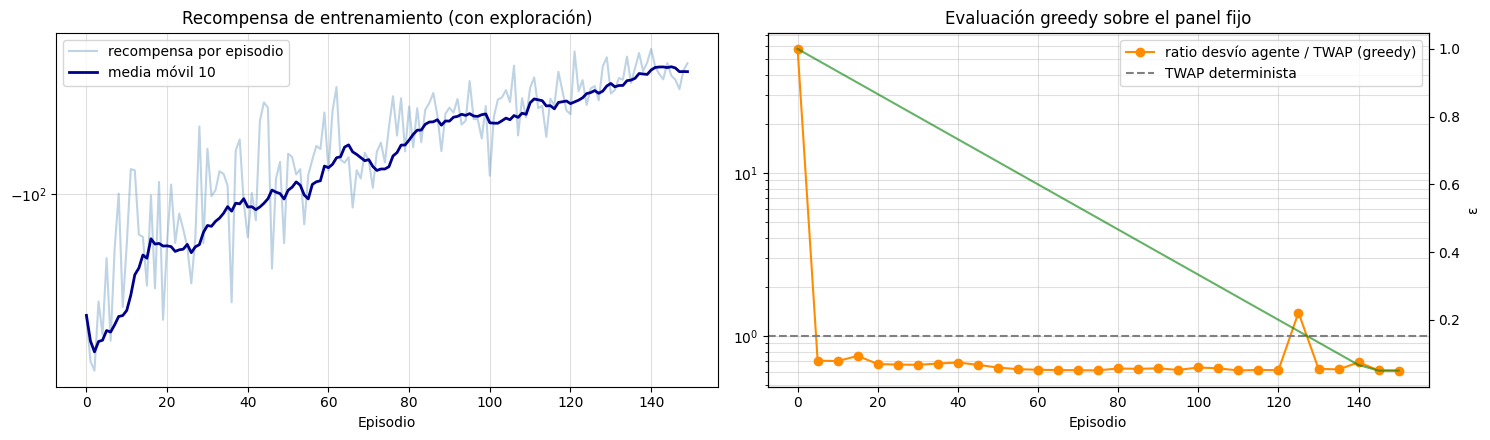

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
rew = pd.Series(history["rewards"])
axes[0].plot(rew, color="steelblue", alpha=0.35, label="recompensa por episodio")
axes[0].plot(rew.rolling(10, min_periods=1).mean(), color="darkblue", lw=2, label="media móvil 10")
axes[0].set_yscale("symlog")
axes[0].set_title("Recompensa de entrenamiento (con exploración)")
axes[0].set_xlabel("Episodio")
axes[0].legend()
axes[0].grid(True, alpha=0.4)

x = eval_df["episode"] + 1
axes[1].plot(x, eval_df["ratio"], "o-", color="darkorange", label="ratio desvío agente / TWAP (greedy)")
axes[1].axhline(1.0, color="grey", ls="--", label="TWAP determinista")
axes[1].set_yscale("log")
axes[1].set_xlabel("Episodio")
axes[1].set_title("Evaluación greedy sobre el panel fijo")
ax_eps = axes[1].twinx()
ax_eps.plot(x, eval_df["epsilon"], color="green", alpha=0.6, label="ε")
ax_eps.set_ylabel("ε")
axes[1].legend(loc="upper right")
axes[1].grid(True, which="both", alpha=0.4)
fig.tight_layout()
fig.savefig(results_dir / "ej2_training.png", dpi=150, bbox_inches="tight")
plt.show()

La recompensa media móvil sube de forma sostenida a medida que baja ε y la evaluación greedy cruza el nivel del TWAP en las primeras decenas de episodios, para estabilizarse por debajo de 1. Hay recaídas puntuales de la política greedy aunque el entrenamiento siga bien (visibles en la curva naranja): es la inestabilidad típica de DQN, y motiva guardar el mejor modelo y parar por aprendizaje (Ejercicio 4C). Se mira la recompensa y el comportamiento, no la *loss*, que cae casi a 0 desde el principio y no dice nada de la política.

### Política aprendida

El mapa siguiente evalúa la red en una rejilla de estados (orden de 50 títulos en 500 bins) y pinta la acción greedy. La diagonal es el plan TWAP.

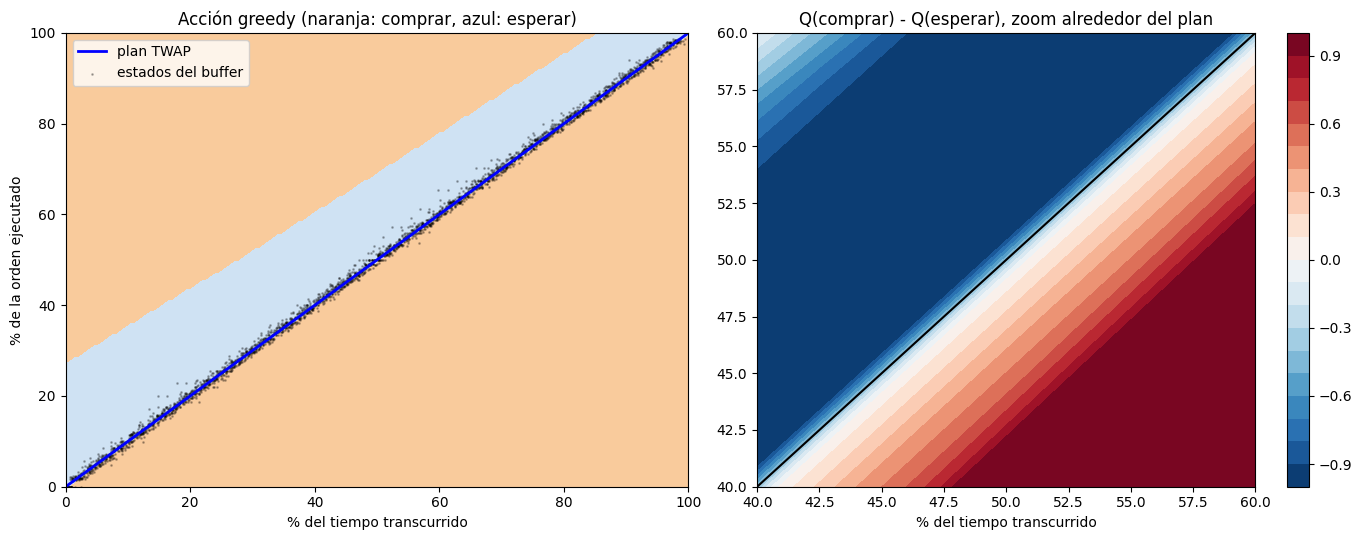

In [5]:
def policy_map(agent: DDQNAgent, V: int = 50, T: int = 500, n: int = 201) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Acción greedy y ventaja Q(comprar) - Q(esperar) en una rejilla (% tiempo, % ejecutado)."""
    t = np.linspace(0, 1, n)
    e = np.linspace(0, 1, n)
    tt, ee = np.meshgrid(t, e)
    dev = np.clip((ee * V - tt * V) / agent.env.dev_clip, -1, 1)
    states = np.stack([1 - tt, 1 - ee, dev], axis=-1).reshape(-1, 3).astype(np.float32)
    q = agent.getQs(states, agent.primary_model)
    return tt, ee, (q[:, 1] - q[:, 0]).reshape(n, n)


tt, ee, adv = policy_map(agent)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].contourf(100 * tt, 100 * ee, (adv > 0).astype(float), levels=[-0.5, 0.5, 1.5], colors=["#cfe2f3", "#f9cb9c"])
axes[0].plot([0, 100], [0, 100], color="blue", lw=2, label="plan TWAP")
# estados realmente visitados (muestra del buffer): fuera de esa nube la red extrapola sin datos
buf = np.array([b[0] for b in list(agent.buffer)[::7]])
axes[0].scatter(100 * (1 - buf[:, 0]), 100 * (1 - buf[:, 1]), s=1, color="black", alpha=0.25, label="estados del buffer")
axes[0].set_title("Acción greedy (naranja: comprar, azul: esperar)")
axes[0].set_xlabel("% del tiempo transcurrido")
axes[0].set_ylabel("% de la orden ejecutado")
axes[0].legend(loc="upper left")
zoom = (tt > 0.4) & (tt < 0.6)
cs = axes[1].contourf(100 * tt, 100 * ee, np.clip(adv, -1, 1), levels=21, cmap="RdBu_r")
axes[1].plot([0, 100], [0, 100], color="black", lw=1.5)
axes[1].set_xlim(40, 60)
axes[1].set_ylim(40, 60)
axes[1].set_title("Q(comprar) - Q(esperar), zoom alrededor del plan")
axes[1].set_xlabel("% del tiempo transcurrido")
fig.colorbar(cs, ax=axes[1])
fig.tight_layout()
fig.savefig(results_dir / "ej2_policy_map.png", dpi=150, bbox_inches="tight")
plt.show()

El agente ha aprendido la regla del TWAP sin que se le haya dado: compra por debajo de la diagonal y espera por encima. La ventaja Q(comprar) - Q(esperar) cambia de signo justo sobre el plan, con una franja de medio título (comprar cuando se va medio título por detrás, que es el redondeo que minimiza el desvío).

La zona naranja de arriba a la izquierda (ir muy por delante del plan y aun así comprar) no es un error de la recompensa: son estados que ni la política ni la exploración visitan nunca (la nube negra son los estados del buffer). Ahí la red extrapola sin datos, y además el desvío del estado está acotado a 5 títulos, así que más allá todos los estados le parecen iguales. No afecta al comportamiento porque nunca se llega a esa zona, pero ilustra un límite del aprendizaje: la política solo es fiable donde se ha explorado.

### Comportamiento en distintos días, horas, duraciones y tamaños

Se evalúa el agente final (sin exploración) en 200 episodios nuevos de train, distintos de los del panel de evaluación, y se compara con el TWAP determinista en los mismos episodios.

In [6]:
robust_seeds = list(range(20_000, 20_200))
agent_rob = evaluate_panel(env, agent, robust_seeds)
twap_rob = twap_panel(env, robust_seeds)
summary_rob = pd.DataFrame({"agente DDQN": summarize_panel(agent_rob), "TWAP determinista": summarize_panel(twap_rob)}).T
save_results_table(summary_rob.reset_index(names="política"), results_dir / "ej2_robustness_summary.csv")
print(f"Días distintos: {agent_rob['day'].nunique()}, duraciones {agent_rob['episode_bins'].min():.0f} a {agent_rob['episode_bins'].max():.0f} bins, "
      f"órdenes de {agent_rob['vol_care'].min():.0f} a {agent_rob['vol_care'].max():.0f} títulos, "
      f"inicio entre {agent_rob['start'].min()} y {agent_rob['start'].max()}")
summary_rob

Días distintos: 59, duraciones 400 a 597 bins, órdenes de 31 a 72 títulos, inicio entre 13:05:00 y 16:49:50


,mean_abs_dev,max_abs_dev,off_plan_steps_pct,completed_pct,time_used_pct,slippage_bps_mean,slippage_bps_std,cum_reward
agente DDQN,0.252,0.617,0.000,100.000,98.875,-3.324,6.492,-25.352
TWAP determinista,0.414,0.924,0.000,100.000,98.233,-3.340,6.558,-41.535


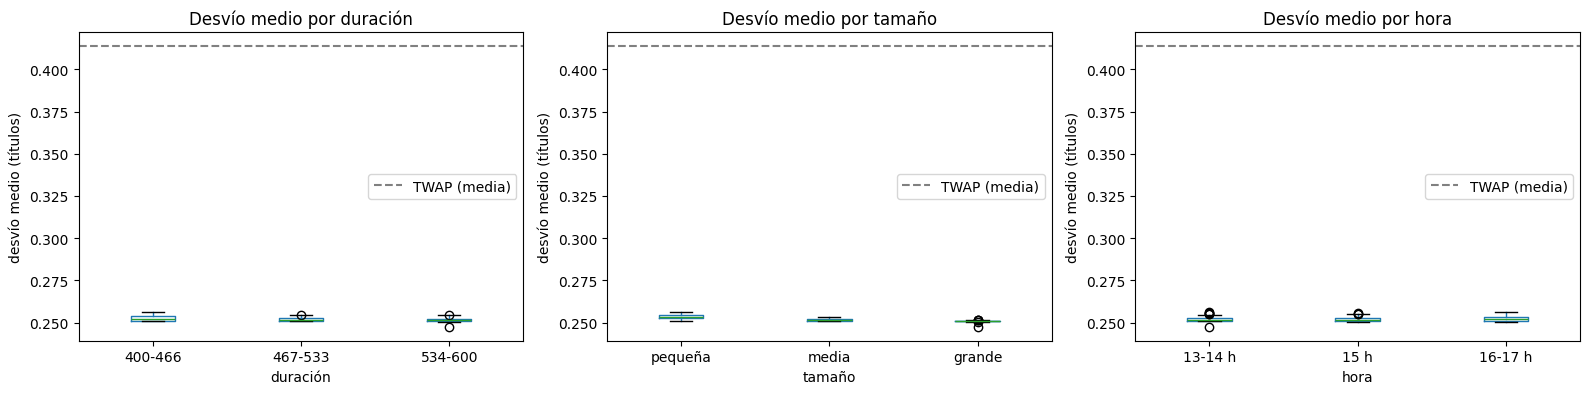

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
agent_rob["duración"] = pd.cut(agent_rob["episode_bins"], [399, 466, 533, 600], labels=["400-466", "467-533", "534-600"])
agent_rob["tamaño"] = pd.qcut(agent_rob["vol_care"], 3, labels=["pequeña", "media", "grande"])
agent_rob["hora"] = pd.cut(pd.to_datetime(agent_rob["start"], format="%H:%M:%S").dt.hour, [12, 14, 15, 17], labels=["13-14 h", "15 h", "16-17 h"])
for ax, col in zip(axes, ["duración", "tamaño", "hora"]):
    agent_rob.boxplot(column="mean_abs_dev", by=col, ax=ax, grid=False)
    ax.axhline(twap_rob["mean_abs_dev"].mean(), color="grey", ls="--", label="TWAP (media)")
    ax.set_title(f"Desvío medio por {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("desvío medio (títulos)")
    ax.legend()
fig.suptitle("")
fig.tight_layout()
fig.savefig(results_dir / "ej2_robustness.png", dpi=150, bbox_inches="tight")
plt.show()

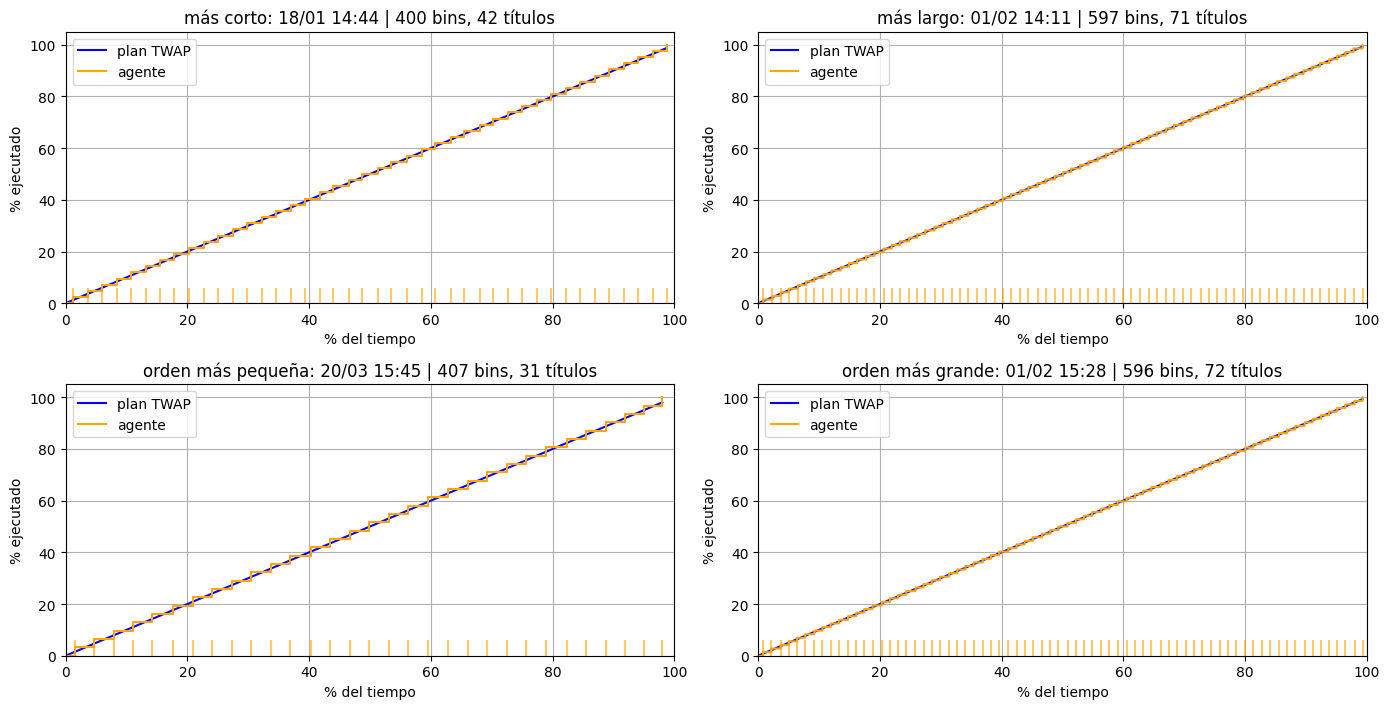

In [8]:
# episodios extremos del panel de robustez: más corto, más largo, orden más pequeña y más grande
picks = {
    "más corto": agent_rob.loc[agent_rob["episode_bins"].idxmin(), "seed"],
    "más largo": agent_rob.loc[agent_rob["episode_bins"].idxmax(), "seed"],
    "orden más pequeña": agent_rob.loc[agent_rob["vol_care"].idxmin(), "seed"],
    "orden más grande": agent_rob.loc[agent_rob["vol_care"].idxmax(), "seed"],
}
traces, labels = [], []
for label, sd in picks.items():
    tr = episode_trace(env, agent, int(sd))
    traces.append(tr)
    labels.append(f"{label}: {tr['time'].iloc[0]:%d/%m %H:%M}")
plot_traces_vs_plan(traces, labels, save_path=results_dir / "ej2_traces.png");

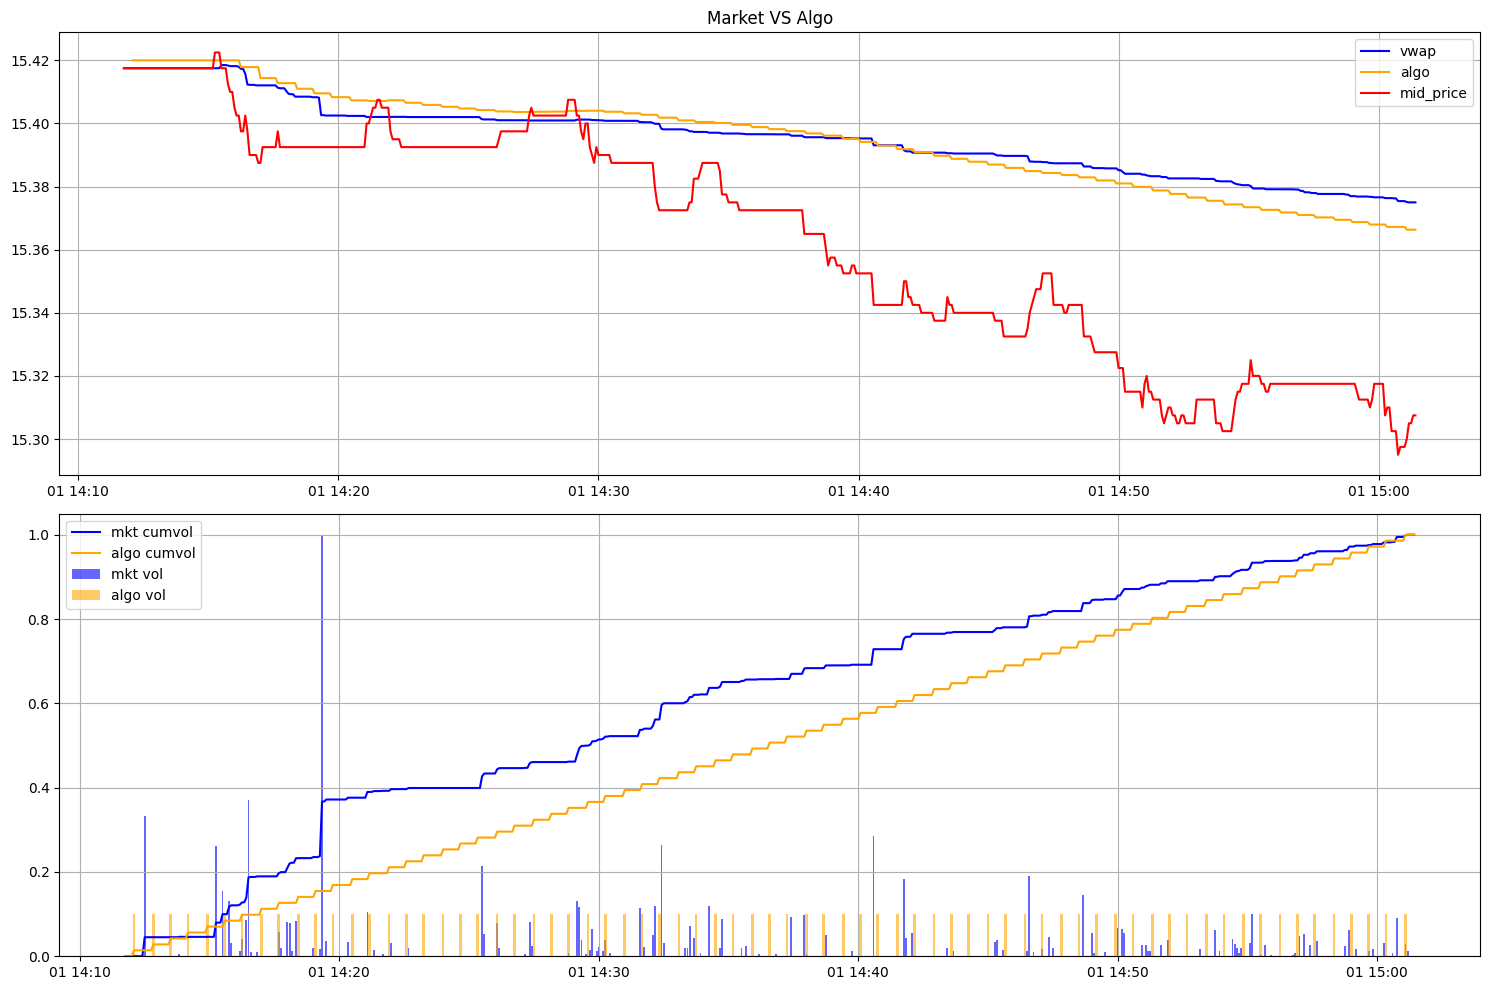

In [9]:
# gráfico del taller (mercado frente a algoritmo), comparable con images/twap_model/twap_reproduction_dqn.png
run_episode(env, agent, seed=int(picks["más largo"]))
plot_results(env, save_path=results_dir / "ej2_market_vs_algo.png");

El volumen acumulado del agente (naranja) sigue la diagonal del plan en todos los casos, con compras equiespaciadas, igual que el gráfico de referencia `twap_reproduction_dqn.png`. El desvío medio no depende de la duración, del tamaño ni de la hora de inicio, y el 100 % de las órdenes se completa.

El slippage frente al VWAP de mercado es prácticamente el mismo que el del TWAP determinista: ambos compran en los mismos momentos aproximados y a `ask1`, mientras que el VWAP de mercado se calcula con el mid. Ese medio spread (unos 2 pbs en REP) es un coste estructural de comprar con orden agresiva y explica que el slippage medio sea negativo. Mejorar el precio no es el objetivo de este ejercicio (es la idea A del Ejercicio 4).

Como comprobación adicional (no la pide el enunciado), sobre 100 episodios de validación (2019), que el agente no ha visto:

In [10]:
env_val = build_env(cfg, split="val")
val_seeds = list(range(30_000, 30_100))
summary_val = pd.DataFrame({
    "agente DDQN": summarize_panel(evaluate_panel(env_val, agent, val_seeds)),
    "TWAP determinista": summarize_panel(twap_panel(env_val, val_seeds)),
}).T
summary_val

,mean_abs_dev,max_abs_dev,off_plan_steps_pct,completed_pct,time_used_pct,slippage_bps_mean,slippage_bps_std,cum_reward
agente DDQN,0.252,0.612,0.000,100.000,98.858,-1.946,4.455,-24.916
TWAP determinista,0.414,0.926,0.000,100.000,98.200,-1.834,4.589,-40.801


## Segunda parte: parametría

| Parámetro | Valor | Motivación |
|---|---|---|
| γ | 0,9 | Horizonte efectivo `1/(1-γ) = 10` steps, del orden de la separación entre compras de un TWAP (`T/V` entre 8 y 13 bins): la consecuencia de comprar ahora o no se nota hasta la siguiente compra prevista. Como la recompensa es densa, no hace falta mirar 500 steps adelante. Con 0,99 los valores Q acumulan ~100 steps de ruido y el aprendizaje es menos estable (barrido). |
| α (Adam) | 1e-3 | Recompensas en [-1, 0] y red pequeña: con 0,01 (Ejercicio 1) los saltos son grandes para una frontera de medio título. No se decae a 0: el problema no es estacionario (la política que genera los datos cambia con ε). |
| Buffer | 20 000 transiciones | Unos 40 episodios: mezcla suficiente de días, horas, duraciones y tamaños para romper la correlación temporal, sin conservar durante cientos de episodios las primeras experiencias casi aleatorias (con 50 000 durarían ~100). Se compara con 2 000. |
| Relleno inicial | 5 000 pasos con ε = 1 | Unos 10 episodios aleatorios antes del primer `learn`, para que los primeros lotes no estén correlacionados. |
| Acción aleatoria | `p = V/T` | Se mantiene la del taller: en media sigue el ritmo del TWAP, así la exploración recorre estados cercanos al plan y llega a los finales de episodio. Con p = 0,5 la orden se completaría en ~2V steps y nunca se visitaría la segunda mitad del tiempo. |
| `learn_after` | 4 | Un paso de gradiente cada 4 transiciones: ~19 000 actualizaciones en 150 episodios frente a ~1 200 con 64 (Ejercicio 1). Se compara con 16. |
| `update_target_after` | 500 | Aproximadamente un episodio: el objetivo se mantiene fijo dentro del episodio y se actualiza a menudo. |
| Batch | 64, con CER | El último elemento siempre entra en el lote (como en el taller). |
| Neuronas | 32 + 32 | Estado de 3 variables y frontera simple. |
| Episodios | 150 | La evaluación greedy se estabiliza mucho antes (ver curvas); el Ejercicio 4C lo convierte en parada por aprendizaje. |
| `force_first_buy` | False | La primera compra la decide la política, no una regla externa. |

Para respaldar las elecciones principales se entrena cada variante con 3 semillas, cambiando un solo parámetro respecto a la configuración base, y se mira la curva del ratio frente al TWAP (mediana y rango entre semillas).

In [11]:
base = ExperimentConfig(name="base (plan, γ=0,9, buffer 20k, learn 4)")
seeds = [0, 1, 2]
variants = {
    "γ = 0,99": dict(gamma=0.99),
    "γ = 0,5": dict(gamma=0.5),
    "buffer 2 000": dict(buffer_size=2_000),
    "learn_after 16": dict(learn_after=16),
    "estado básico (2 variables)": dict(state_mode="basic"),
}
configs = with_seeds(base, seeds)
for name, changes in variants.items():
    configs += with_seeds(base, seeds, name=name, **changes)
sweep = run_many(configs, n_jobs=N_JOBS)
sweep_df = eval_curves(sweep)
save_results_table(sweep_df, results_dir / "ej2_sweep.csv")
print(f"{len(sweep)} entrenamientos completados")

18 entrenamientos completados


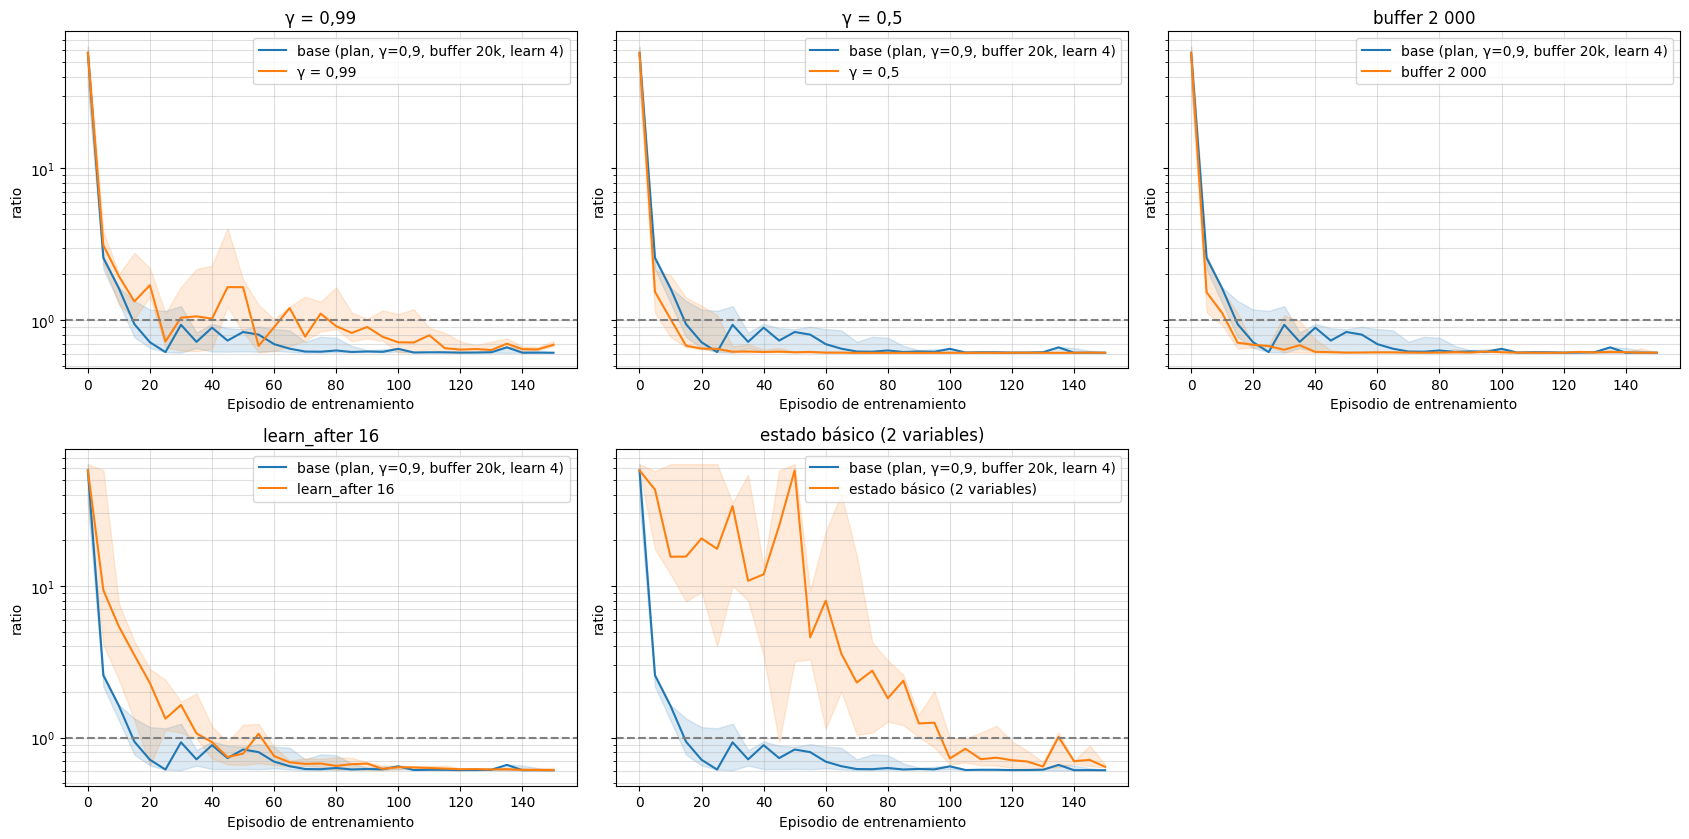

,episodio en que iguala al TWAP,ratio final,ratio medio últimos 50 ep.,ratio máximo últimos 50 ep.
name,,,,
"base (plan, γ=0,9, buffer 20k, learn 4)",15.000,0.610,0.619,0.662
buffer 2 000,15.000,0.611,0.615,0.635
estado básico (2 variables),100.000,0.643,0.717,1.083
learn_after 16,35.000,0.610,0.621,0.637
"γ = 0,5",15.000,0.611,0.610,0.612
"γ = 0,99",25.000,0.689,0.680,0.889


In [12]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5), sharey=True)
base_df = sweep_df[sweep_df["name"] == base.name]
for ax, name in zip(axes.flat, variants):
    sub = pd.concat([base_df, sweep_df[sweep_df["name"] == name]])
    plot_eval_curves(sub, "ratio", ax=ax, logy=True, title=name)
    ax.axhline(1.0, color="grey", ls="--")
axes.flat[-1].axis("off")
fig.tight_layout()
fig.savefig(results_dir / "ej2_sweep.png", dpi=150, bbox_inches="tight")
plt.show()


def first_below(g: pd.DataFrame, thr: float = 1.0) -> float:
    hit = g.loc[g["ratio"] <= thr, "episode"]
    return float(hit.iloc[0] + 1) if len(hit) else np.nan


sweep_summary = (
    sweep_df.groupby(["name", "seed"])
    .apply(lambda g: pd.Series({
        "episodio en que iguala al TWAP": first_below(g),
        "ratio final": g["ratio"].iloc[-1],
        "ratio medio últimos 50 ep.": g.loc[g["episode"] >= 100, "ratio"].mean(),
        "ratio máximo últimos 50 ep.": g.loc[g["episode"] >= 100, "ratio"].max(),
    }), include_groups=False)
    .groupby("name", sort=False).median()
)
save_results_table(sweep_summary.reset_index(), results_dir / "ej2_sweep_summary.csv")
sweep_summary

**Lectura del barrido** (medianas de 3 semillas en la tabla):

* **Estado.** Con las dos variables del taller el agente también aprende el TWAP, lo que confirma que el estado mínimo basta, pero tarda unas 6 veces más en igualar al TWAP, acaba algo peor y tiene recaídas por encima de 1. El desvío explícito acelera y estabiliza el aprendizaje.
* **γ.** γ = 0,99 es la peor variante: tarda más en igualar al TWAP, queda en un ratio medio más alto en los últimos 50 episodios y tiene los picos más altos, coherente con que sus valores Q integran ~100 steps de ruido. γ = 0,5 da un resultado igual o algo más estable que 0,9: confirma que la recompensa densa hace la decisión casi miope y que es la recompensa, no el descuento, la que transmite el objetivo. Se mantiene γ = 0,9 porque su horizonte cubre la siguiente compra prevista, y porque en el Ejercicio 4 las consecuencias (horizonte del 90 %, precio dentro de una banda) llegan más lejos que un step.
* **Buffer.** Con 2 000 transiciones (unos 4 episodios) el resultado es el mismo: en esta tarea, de estado pequeño y frontera simple, la correlación entre muestras no penaliza. Se mantiene 20 000 por prudencia, porque un buffer de 4 episodios solo contiene unos pocos días y tamaños de orden; no es una elección que el barrido demuestre necesaria.
* **Frecuencia de aprendizaje.** Con `learn_after = 16` hay 4 veces menos actualizaciones y se tarda más del doble en igualar al TWAP.

## Conclusiones del Ejercicio 2

* La recompensa `-κ·|desvío|`, densa y con el cierre descontado, basta para que un Double DQN aprenda un TWAP sin reglas externas; antes de entrenar ya se comprueba que puntúa mejor al TWAP que a cualquier alternativa.
* El agente sigue el plan mejor que la regla determinista del taller (ratio < 1) y se mantiene así en 200 episodios con días, horas, duraciones y tamaños distintos, y también en validación.
* La parametría se apoya en la escala del problema: γ con horizonte igual a la separación entre compras, buffer de ~40 episodios, una actualización cada 4 transiciones.